# From macro paths to loss rates: scenario paths, satellites and a skewed-t severity

**Question:** What does a published macro scenario need before Banco Andino's satellites can read it, and how much higher does
the credit-card loss rate go under the Federal Reserve, EBA and NGFS scenarios than in the baseline?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic; notebooks 02 and 03 are not needed
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- say what a macro stress test is made of (a scenario path, satellite models and a capital engine) and which of those three
  this notebook covers;
- read the vintage and provider of each of the four scenarios of the case and see the engine refuse a path published after
  the observation date;
- transpose a published path onto the bank's jump-off: the Federal Reserve path as it is, the EBA annual path converted to
  quarters, and the NGFS deviation path added to its baseline, each with the engine's path functions;
- read a satellite regression, project it under a scenario by hand for one quarter and with `project_scenario` for twelve,
  and obtain the loss rates and the credit loss of each year;
- run the mechanics of two more scenario tools of the engine, the VAR conditional forecast and the Azzalini-Capitanio
  skewed-t fit of growth-at-risk, and say what each needs that the committed files do not hold.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. 
The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Imports, versions and the reader of the committed documents (three folders below the repository root)
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats
from riskvalidation.stress import paths, satellites, scenario_models

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the scenario side of **C18** (Banco Andino): four scenario variants and the satellites' models document.

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 1.0.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** the four variant documents `data/derived/C18/baseline.json` and `fed-2026-severely-adverse.json` (Federal Reserve 2026, quarterly), `eba-2025-adverse.json` (EBA and ESRB 2025, annual, United States rows) and `ngfs-delayed-transition.json` (NGFS Phase V, NiGEM deviations from the baseline run, annual), and the models document `data/derived/C18/models-banco-andino.json` (the fitted satellites: coefficients, standard errors, sample windows). Each variant's `outputs.scenario` holds the published path, its transposition and its vintage; `outputs.satellites` the projected rates; `outputs.losses` the credit loss by year; `outputs.backcast` the realised rates 2020 to 2025.
- **What is not committed:** the Federal Reserve history 1985 to 2019 and the charge-off series the satellites were fitted on. Step 5 therefore **projects** the fitted satellites with the committed coefficients, but cannot **refit** them; the fit is `fit_satellite`, run by the pipeline on the raw files.
- **The adaptation, stated.** The paths are United States and euro-area paths; Banco Andino is Chilean and synthetic. Each path is transposed onto the bank's own jump-off value and the satellites are fitted on United States charge-off rates, so every loss rate of this notebook carries the label `us-calibrated-adaptation` in the documents. It teaches the machinery, not a forecast for Chile.

In [2]:
# The four scenario variants, the satellites' models document and a picker of one path of a scenario
VARIANTS = {"baseline": "baseline", "eba": "eba-2025-adverse", "fed": "fed-2026-severely-adverse",
            "ngfs": "ngfs-delayed-transition"}
docs = {key: read_json(f"C18/{name}.json") for key, name in VARIANTS.items()}
models = read_json("C18/models-banco-andino.json")["fit"]
AS_OF = docs["baseline"]["outputs"]["bank"]["as_of"]
SCENARIO = {"baseline": "Fed baseline", "eba": "EBA 2025 adverse",
            "fed": "Fed 2026 severely adverse", "ngfs": "NGFS delayed transition"}
LOAN = {"commercial-industrial": "commercial and industrial",
        "commercial-real-estate": "commercial real estate",
        "residential": "residential mortgages", "credit-cards": "credit cards",
        "other-consumer": "other consumer"}
quarters = np.arange(1, 13)


def path_of(key, regressor):
    return next(p for p in docs[key]["outputs"]["scenario"]["paths"] if p["maps_to_regressor"] == regressor)

## Method

### Step 1: the scenarios and their vintage

A macro stress test has three layers (dossier 05, H.1): a **scenario generator** for macro-financial paths over a two to three year horizon, **satellite models** that map the paths to risk parameters, and a **capital engine** that turns losses and revenues into capital ratios (notebook 05). This notebook covers the first two.

Every scenario is a published document with a date, its **vintage**. A scenario published after the date a model is observed would let the future into the validation, so the engine's `check_vintage` refuses a path whose vintage postdates the observation date and accepts equal dates.

The next cell checks the vintage of each scenario against the bank's observation date with `check_vintage`, prints provider,
vintage and the variables each scenario supplies, and then offers the engine a path dated one month after the observation.

In [3]:
# Check each scenario's vintage with the engine and show the refusal of a path published after the observation
for key, doc in docs.items():
    scenario = doc["outputs"]["scenario"]
    paths.check_vintage(scenario["vintage_date"], AS_OF)
    variables = [p["maps_to_regressor"] for p in scenario["paths"]]
    print(f"{SCENARIO[key]:30s} {scenario['provider']:9s} {scenario['vintage_date']}  {variables}")
print("observation date of the bank", AS_OF)
try:
    paths.check_vintage("2026-09-30", AS_OF)
except ValueError:
    print("a path dated 2026-09-30 is refused")

Fed baseline                   fed       2026-02-04  ['unemployment_rate', 'real_gdp_growth', 'prime_rate']
EBA 2025 adverse               eba-esrb  2025-02-26  ['real_gdp_growth', 'unemployment_rate', 'treasury_10y']
Fed 2026 severely adverse      fed       2026-02-04  ['unemployment_rate', 'real_gdp_growth', 'prime_rate']
NGFS delayed transition        ngfs      2024-11-01  ['unemployment_rate', 'prime_rate', 'treasury_10y', 'real_gdp_growth']
observation date of the bank 2026-08-31
a path dated 2026-09-30 is refused


### Step 2: the shape of a path on the bank's jump-off

The satellites run from the bank's last observed quarter, 2025 Q4, not from the date of the scenario's own jump-off. The engine therefore **transposes** a published path onto the target: the shape of the path, its change from its own jump-off, is kept and added to the bank's last observed value (decision Q6 of the case),

$$\tilde x_t = x^{\text{target}}_{0} + \left(x_t - x^{\text{source}}_{0}\right), \qquad t = 1, \dots, 12,$$

which `transpose_path(levels, source_jump_off, target_value, n)` implements. For the Federal Reserve scenarios the source jump-off is 2025 Q4 and the target is the same quarter, so the transposition changes nothing: the first test of the machinery is that it returns the published path.

The next cell takes the unemployment rate of the severely adverse scenario, calls `transpose_path` with the source jump-off
and the bank's value, and draws the published quarters, the transposed path and the committed one.

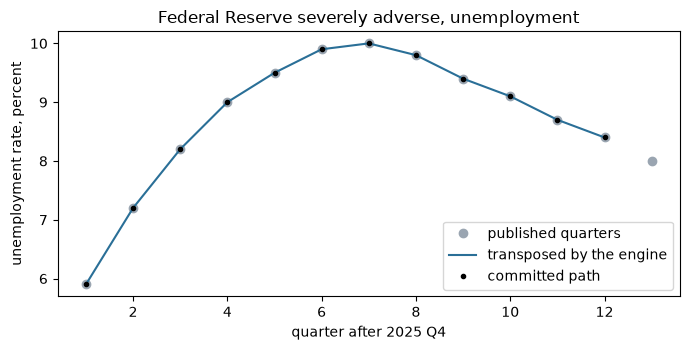

source jump-off and target 4.5 4.5
published quarters [ 5.9  7.2  8.2  9.   9.5  9.9 10.   9.8  9.4  9.1  8.7  8.4  8. ]


In [4]:
# Transpose the Federal Reserve severely adverse unemployment path and draw it against the committed one
unemployment = path_of("fed", "unemployment_rate")
published = np.array([row["value"] for row in unemployment["levels"]])
jump = unemployment["transposition"]["source_jump_off"]["value"]
target = unemployment["transposition"]["target"]["value"]
transposed = paths.transpose_path(published, jump, target, 12)
baked = np.array([row["value"] for row in unemployment["transposed"]])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(np.arange(1, 14), published, "o", color="#9aa5b1", label="published quarters")
ax.plot(quarters, transposed, color="#2a6f97", label="transposed by the engine")
ax.plot(quarters, baked, "k.", label="committed path")
ax.set_xlabel("quarter after 2025 Q4")
ax.set_ylabel("unemployment rate, percent")
ax.set_title("Federal Reserve severely adverse, unemployment")
ax.legend()
fig.tight_layout()
plt.show()
print("source jump-off and target", jump, target)
print("published quarters", published)

The three series lie on top of each other: the Federal Reserve path starts from the same quarter, 2025 Q4, as the bank, so the
source jump-off and the target are both 4.5 percent and the transposition leaves the path as it is. Unemployment climbs from
5.9 percent in the first quarter to a peak of 10.0 in the seventh and falls back to 8.4 in the twelfth. A transposition that
changes nothing is the first test of the machinery, and the next two providers, whose jump-offs do not match the bank's,
are the ones where it earns its place.

### Step 3: the EBA path, from annual to quarterly

The EBA and ESRB publish annual levels for 2025, 2026 and 2027 only. The satellites are quarterly, so `annual_to_quarterly(year_end_levels, jump_off_level)` joins the year-end levels linearly from the jump-off level: quarter $k$ of a year is $\text{prev} + (\text{cur} - \text{prev})\,k/4$, and the fourth quarter is the year-end level itself. Whether the workbook's values are year averages or year-end values is UNVERIFIED in the research record, and the engine treats them as year-end levels. The jump-off of the EBA scenario is 2024 Q4 (the base year of the exercise), while the bank's is 2025 Q4, so the transposition now matters: the shape is kept and added to the bank's 2025 Q4 value.

The next cell converts the EBA year-end levels of unemployment and GDP growth to quarters with `annual_to_quarterly`,
transposes them with `transpose_path` and draws the three stages: the year-end levels, the quarterly join and the transposed path.

unemployment_rate year-end levels [ 8.914 10.046  8.647]
jump-off and bank value 4.081 4.5
shift of the path 0.42
real_gdp_growth year-end levels [-5.055 -2.454  4.28 ]
jump-off and bank value 2.765 1.0
shift of the path -1.76


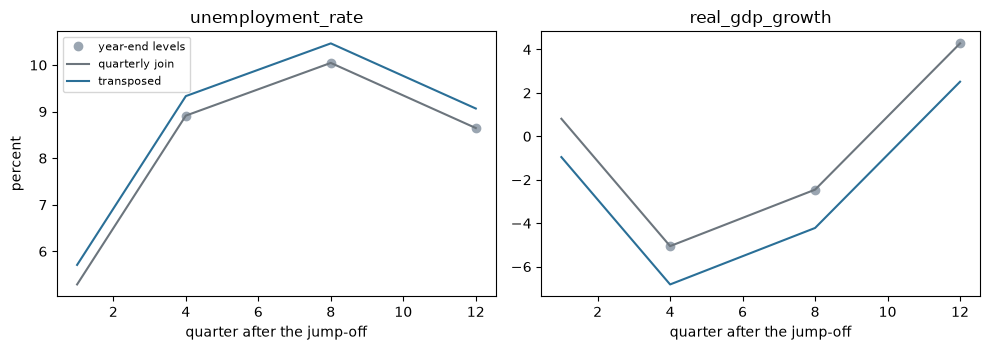

In [5]:
# Convert the EBA annual levels to quarters, transpose them onto the bank's jump-off and draw the three stages
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, regressor in zip(axes, ("unemployment_rate", "real_gdp_growth")):
    p = path_of("eba", regressor)
    year_end = np.array([row["value"] for row in p["levels"]])
    source_jump = p["transposition"]["source_jump_off"]["value"]
    bank_value = p["transposition"]["target"]["value"]
    quarterly = paths.annual_to_quarterly(year_end, source_jump)
    moved = paths.transpose_path(quarterly, source_jump, bank_value, 12)
    ax.plot(quarters[3::4], year_end, "o", color="#9aa5b1", label="year-end levels")
    ax.plot(quarters, quarterly, color="#6c757d", label="quarterly join")
    ax.plot(quarters, moved, color="#2a6f97", label="transposed")
    ax.set_title(regressor)
    ax.set_xlabel("quarter after the jump-off")
    print(regressor, "year-end levels", np.round(year_end, 3))
    print("jump-off and bank value", round(source_jump, 3), bank_value)
    print("shift of the path", round(bank_value - source_jump, 2))
axes[0].set_ylabel("percent")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

The EBA publishes three annual levels, so the dots are 8.91, 10.05 and 8.65 percent of unemployment at the end of 2025, 2026
and 2027; the grey line joins them linearly from the exercise's jump-off at 4.08, and the blue line is the same shape moved up
by 0.42 points because the bank's own jump-off is 4.5. Growth goes the other way, 1.76 points down, because the bank starts
from 1.0 percent against the EBA's 2.77. The transposition keeps the shape of the shock and replaces the starting point,
which is the choice the case made (decision Q6); it assumes the bank would feel the EBA's change, not its level.

### Step 4: the NGFS path, a deviation from a baseline run

The NGFS Phase V runs publish, for each scenario, the **deviation** from the Baseline run, so a scenario level is the baseline level plus the deviation (a percent difference for GDP): `level_from_deviation(baseline, deviation, kind)` with `kind` equal to `plus` or `percent`. The delayed-transition policy shock acts in **2031 to 2033** in the NGFS runs, so the case takes those three years and transposes them onto the bank's 2025 Q4 jump-off: the shape of the shock, not its calendar.

The next cell rebuilds the NGFS unemployment and policy-rate levels as the baseline run plus the deviation with
`level_from_deviation`, converts them to quarters and transposes them, and draws the baseline run, the rebuilt levels and the
transposed path.

A published path ends at a horizon, and the satellites may need more quarters. `revert_to_baseline(path, baseline_tail, n, reversion_quarters)`
extends a path past its end by moving it linearly back to the baseline tail in `reversion_quarters` steps (a convention of the
case, 12). The cell after the figure extends the severely adverse unemployment path of step 2 to 24 quarters, which the
committed 12-quarter horizon does not use.

unemployment_rate baseline run [4.442 4.494 4.537] deviation [0.106 0.408 0.324]
prime_rate baseline run [3.25 3.25 3.25] deviation [ 0.03  -0.57  -0.603]


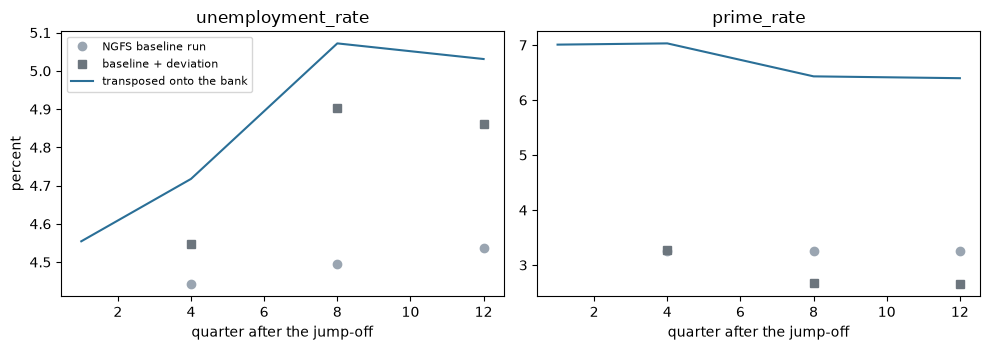

policy shock window 2031 2033


In [6]:
# Rebuild the NGFS levels as baseline + deviation, convert, transpose and draw the stages
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, regressor in zip(axes, ("unemployment_rate", "prime_rate")):
    p = path_of("ngfs", regressor)
    baseline_run = np.array([row["value"] for row in p["level_rule"]["baseline"]])
    deviation = np.array([row["value"] for row in p["source"]])
    rebuilt = paths.level_from_deviation(baseline_run, deviation, "plus")
    source_jump = p["transposition"]["source_jump_off"]["value"]
    bank_value = p["transposition"]["target"]["value"]
    moved = paths.transpose_path(paths.annual_to_quarterly(rebuilt, source_jump), source_jump, bank_value, 12)
    ax.plot(quarters[3::4], baseline_run, "o", color="#9aa5b1", label="NGFS baseline run")
    ax.plot(quarters[3::4], rebuilt, "s", color="#6c757d", label="baseline + deviation")
    ax.plot(quarters, moved, color="#2a6f97", label="transposed onto the bank")
    ax.set_title(regressor)
    ax.set_xlabel("quarter after the jump-off")
    print(regressor, "baseline run", np.round(baseline_run, 3), "deviation", np.round(deviation, 3))
axes[0].set_ylabel("percent")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
window = docs["ngfs"]["outputs"]["scenario"]["policy_shock_window"]
print("policy shock window", window["start_year"], window["end_year"])

The NGFS does not publish a level but a deviation from its baseline run, so the unemployment levels are 4.547, 4.902 and
4.861 percent for the three years of the shock, 0.11, 0.41 and 0.32 points above a baseline of about 4.5, and the policy rate
falls by 0.57 to 0.60 points. The shock is small compared with the Federal Reserve's, which is why this scenario will rank
close to the baseline in the Results. The case takes the 2031 to 2033 window of the policy shock and moves it to the bank's
2025 Q4 jump-off, keeping the shape of the shock and not its calendar.

The next cell extends the Federal Reserve severely adverse unemployment path of step 2 from 12 to 24 quarters with
`revert_to_baseline`, moving it back towards the baseline tail in 12 steps, and draws the extension.

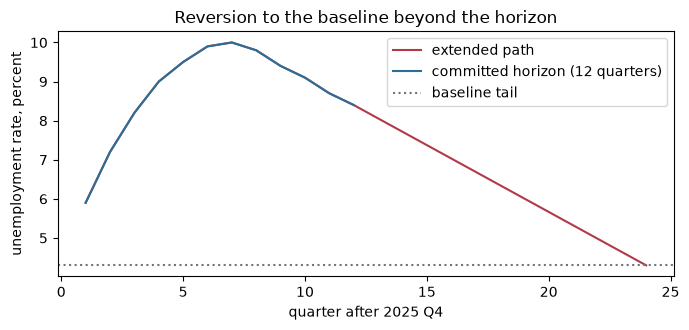

baseline tail 4.3 last quarters [5.32 4.98 4.64 4.3 ]


In [7]:
# Extend the severely adverse unemployment path to 24 quarters by reverting to the baseline tail
baseline_tail = path_of("baseline", "unemployment_rate")["transposed"][-1]["value"]
extended = paths.revert_to_baseline(transposed, baseline_tail, 24, 12)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.arange(1, 25), extended, color="#b23a48", label="extended path")
ax.plot(quarters, transposed, color="#2a6f97", label="committed horizon (12 quarters)")
ax.axhline(baseline_tail, color="#6c757d", linestyle=":", label="baseline tail")
ax.set_xlabel("quarter after 2025 Q4")
ax.set_ylabel("unemployment rate, percent")
ax.set_title("Reversion to the baseline beyond the horizon")
ax.legend()
fig.tight_layout()
plt.show()
print("baseline tail", baseline_tail, "last quarters", np.round(extended[-4:], 2))

After the twelfth quarter, where the published path ends at 8.4 percent, the extension walks back in a straight line and
reaches the baseline tail of 4.3 percent twelve quarters later. The straight line is a convention of the case, not an estimate
of how unemployment recovers, and it only matters for a satellite that needs more than the twelve quarters the committed
horizon uses, which none of the case's five satellites does. It is shown because a path that stops abruptly would otherwise
be read as a path that stays at its last value.

### Step 5: a satellite, by hand and with the engine

A satellite explains the loss rate $DR_t$ of a loan type by the macro variables, through a link $g$ (dossier 04, I.1 and dossier 05, H.1 layer 2):

$$g(DR_t) = \alpha + \sum_{k=1}^{p}\phi_k\, g(DR_{t-k}) + \sum_{j,\ell}\beta_{j\ell}\, X_{j,t-\ell} + \varepsilon_t.$$

With the **probit** link, $g = \Phi^{-1}$, the regression is a regression of the latent credit cycle of Vasicek's one-factor model on the macro variables, which is why the link is consistent with the portfolio models of topic 06. The segments whose rate is zero or negative in some quarters (net recoveries of real estate) use the identity link. In the case $p = 1$, the regressors are real GDP growth and the unemployment rate at lags 0 and 1, and each satellite is fitted by ordinary least squares on 1985 to 2019 (1991 to 2019 for the two real estate types).

The next cell reads the committed coefficients of the commercial-and-industrial satellite, takes the last realised rate (2025 Q4, from the back-cast block) and computes **the first projected quarter by hand**: link of the last rate, each term of the equation, the sum and the inverse link. It then calls `project_scenario` for all twelve quarters and for all five loan types under the Federal Reserve severely adverse scenario, and compares with the committed rates.

In [8]:
# The Federal Reserve severely adverse regressors, the last realised rates and the committed projected rates
REGRESSORS = ("real_gdp_growth", "unemployment_rate")
fed_paths = {p["maps_to_regressor"]: p for p in docs["fed"]["outputs"]["scenario"]["paths"]}
X = np.column_stack([[row["value"] for row in fed_paths[name]["transposed"]] for name in REGRESSORS])
jump_off = np.array([[fed_paths[name]["transposition"]["target"]["value"] for name in REGRESSORS]])
backcast = docs["fed"]["outputs"]["backcast"]["per_loan_type"]
last_rate = {b["fed_loan_type"]: b["quarters"][-1]["realised"] for b in backcast}
fed_types = docs["fed"]["outputs"]["satellites"]["fed_loan_types"]
committed_rates = {t["fed_loan_type"]: np.array([q["rate"] for q in t["quarters"]]) for t in fed_types}
ci = next(m for m in models["satellites"] if m["fed_loan_type"] == "commercial-industrial")
coef = {c["name"]: c["estimate"] for c in ci["coefficients"]}

The next cell computes the first projected quarter of the commercial-and-industrial satellite by hand: the probit link of the
last realised rate, each term of the equation, their sum and the inverse link, using `link` and `inverse_link` of the engine.
The bars show the six terms in the link scale.

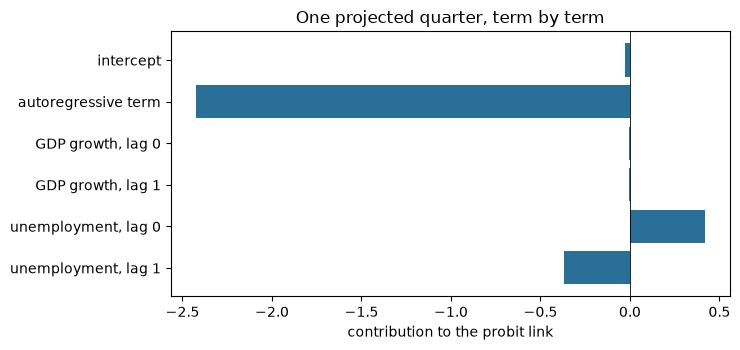

last realised rate and its link 0.005600000000000001 -2.5364
sum of the terms and projected rate -2.4138 0.007894


In [9]:
# The first projected quarter of the commercial-industrial satellite by hand, term by term
g0 = satellites.link("probit", np.array([last_rate["commercial-industrial"]]))[0]
terms = {"intercept": coef["intercept"],
         "autoregressive term": coef["ar_1"] * g0,
         "GDP growth, lag 0": coef["real_gdp_growth_lag0"] * X[0, 0],
         "GDP growth, lag 1": coef["real_gdp_growth_lag1"] * jump_off[0, 0],
         "unemployment, lag 0": coef["unemployment_rate_lag0"] * X[0, 1],
         "unemployment, lag 1": coef["unemployment_rate_lag1"] * jump_off[0, 1]}
link_value = sum(terms.values())
rate = float(satellites.inverse_link("probit", np.array([link_value]))[0])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(list(terms)[::-1], list(terms.values())[::-1], color="#2a6f97")
ax.axvline(0, color="black", linewidth=0.6)
ax.set_xlabel("contribution to the probit link")
ax.set_title("One projected quarter, term by term")
fig.tight_layout()
plt.show()
print("last realised rate and its link", last_rate["commercial-industrial"], round(float(g0), 4))
print("sum of the terms and projected rate", round(link_value, 4), round(rate, 6))

Five of the six terms are small. The autoregressive term, minus 2.42, is the link value of last quarter's rate and dominates,
so the loss rate is mostly persistence; the macro variables move it at the margin, unemployment adding 0.42 in the current
quarter and taking back 0.37 through its lag. The sum, minus 2.41, goes through the inverse link to a rate of 0.007894 for the
first quarter, up from 0.0056 realised. A satellite is nothing more than this equation, which is why it can be projected
from committed coefficients without refitting.

The next cell rebuilds a `SatelliteFit` of the engine from the committed coefficients of each of the five satellites; that
small adapter only maps the document's keys onto the engine's constructor.

In [10]:
# Rebuild the engine's SatelliteFit of each loan type from the committed coefficients
def satellite_fit(model):
    names = list(dict.fromkeys(r["name"] for r in model["regressors"]))
    coefficients = model["coefficients"]
    return satellites.SatelliteFit(
        link=model["link"], window_start=model["sample_window"]["start"], window_end=model["sample_window"]["end"],
        n_obs=model["n_obs"], ar_order=model["ar_order"], regressor_names=tuple(names),
        lags=tuple(sorted({r["lag"] for r in model["regressors"]})),
        coefficient_names=tuple(c["name"] for c in coefficients),
        estimates=tuple(c["estimate"] for c in coefficients),
        std_errors=tuple(c["std_error"] for c in coefficients), r_squared=model["fit_statistics"]["r_squared"],
        residual_sd=model["fit_statistics"]["residual_sd"])


fits = {m["fed_loan_type"]: satellite_fit(m) for m in models["satellites"]}
for loan_type, fit in fits.items():
    print(f"{LOAN[loan_type]:26s} {fit.link:8s} n_obs {fit.n_obs:3d}  R2 {fit.r_squared:.3f}")

commercial and industrial  probit   n_obs 139  R2 0.942
commercial real estate     identity n_obs 115  R2 0.959
residential mortgages      identity n_obs 115  R2 0.954
credit cards               probit   n_obs 139  R2 0.926
other consumer             probit   n_obs 139  R2 0.910


The next cell calls `project_scenario` for the twelve quarters of the severely adverse scenario for each of the five loan types
and draws the projected rates. It also prints the largest gap between each projection and the committed rates, the one
reproduction check of this notebook.

commercial and industrial  peak rate 0.0180  gap 0.0e+00
commercial real estate     peak rate 0.0179  gap 0.0e+00
residential mortgages      peak rate 0.0114  gap 0.0e+00
credit cards               peak rate 0.0873  gap 0.0e+00
other consumer             peak rate 0.0206  gap 0.0e+00


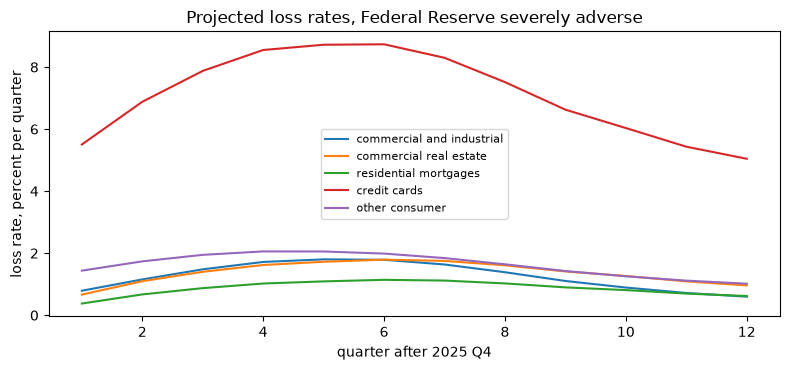

In [11]:
# Project the five satellites under the severely adverse scenario and draw the rates
fig, ax = plt.subplots(figsize=(8, 3.8))
for loan_type, fit in fits.items():
    start = satellites.link(fit.link, np.array([last_rate[loan_type]]))
    projection = satellites.project_scenario(fit, start, jump_off, X)
    ax.plot(quarters, projection.rates * 100, label=LOAN[loan_type])
    gap = float(np.max(np.abs(projection.rates - committed_rates[loan_type])))
    print(f"{LOAN[loan_type]:26s} peak rate {projection.rates.max():.4f}  gap {gap:.1e}")
ax.set_xlabel("quarter after 2025 Q4")
ax.set_ylabel("loss rate, percent per quarter")
ax.set_title("Projected loss rates, Federal Reserve severely adverse")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Every satellite rises in the first year and then eases as unemployment turns, with the credit-card rate far above the rest, at
a peak of 8.73 percent a quarter, and residential mortgages at the bottom with 1.14. The printed gap to the committed rates is
zero for the five, which means that the committed file is exactly what the engine gives from its coefficients and path; the
gap is printed once here and the rest of the notebook trusts it. The five satellites have an $R^2$ between 0.910 and 0.959 on
115 to 139 quarters, in-sample, so these are projections of a fitted relation and not out-of-sample forecasts.

**From loan types to the bank's credit loss.** Banco Andino's book is in three classes, each mapped to Federal Reserve loan
types with fixed weights (an adaptation of the case): commercial = 0.6 C&I + 0.4 commercial real estate, consumer = 0.5 credit
cards + 0.5 other consumer, mortgage = residential. The credit loss of a year is the exposure of each class times the mean of
the four quarterly rates of the year, summed over classes. The next cell builds the class rates from the weights and draws
the annual credit loss of each class.

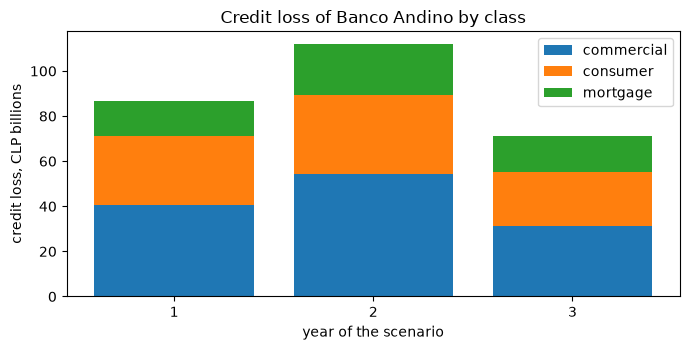

credit loss by year, CLP millions [ 86518.6 111986.8  71005.1]
committed [86518.6, 111986.8, 71005.1]


In [12]:
# Class rates from the loan-type weights and the exposure, then the credit loss of each year by class
classes = docs["fed"]["outputs"]["satellites"]["banco_andino_classes"]
CLASS = {"commercial": "commercial", "consumer": "consumer", "mortgage": "mortgage"}
yearly = {}
for klass in classes:
    class_rate = sum(w * committed_rates[t] for t, w in zip(klass["maps_from"], klass["weights"]))
    yearly[klass["banco_andino_class"]] = class_rate.reshape(3, 4).mean(axis=1) * klass["exposure_clp_m"] / 1e3
fig, ax = plt.subplots(figsize=(7, 3.6))
bottom = np.zeros(3)
for name, values in yearly.items():
    ax.bar(["1", "2", "3"], values, bottom=bottom, label=CLASS[name])
    bottom += values
ax.set_xlabel("year of the scenario")
ax.set_ylabel("credit loss, CLP billions")
ax.set_title("Credit loss of Banco Andino by class")
ax.legend()
fig.tight_layout()
plt.show()
print("credit loss by year, CLP millions", np.round(bottom * 1e3, 1))
print("committed", [round(row["credit"], 1) for row in docs["fed"]["outputs"]["losses"]["scenario_losses"]])

Commercial lending is the largest class, with a loss of about CLP 40 to 54 billion a year, consumer lending is smaller in
exposure but loses nearly as much per year because its rates are the highest, and mortgages add 15 to 23 billion. The
total peaks in the second year, at CLP 111,986.8 million, between 86,518.6 in the first year and 71,005.1 in the third, which
is the shape of the unemployment path with a lag. These are credit losses only; the capital plan of notebook 05 adds the
other risks, revenue and the balance sheet.

### Step 6: a VAR and a conditional forecast

The satellites map two chosen macro variables to loss rates. A **vector autoregression** models several variables together, $y_t = c + \sum_{l=1}^{p} A_l\, y_{t-l} + u_t$ (dossier 05, H.2), and a stress scenario is then a **conditional forecast**: the path of a subset of the variables is given, the others follow from the model, with the shocks of the free variables correlated with those of the conditioned ones. `fit_var(y, lags)` estimates it by OLS equation by equation and `var_conditional_forecast(fit, y_history, path, conditioned)` computes the conditional paths (the period-by-period form; the full-horizon form of Waggoner and Zha is UNVERIFIED against the paper).

The case does not bake a VAR, and the committed files hold no macro history to fit one on. What they do hold are real quarterly charge-off rates for 2020 to 2025 (the realised rates of the back-cast block), so the next cell runs the **mechanics** on those: a VAR(1) of the commercial-and-industrial rate and the credit-card rate (24 quarters, a short sample that only a demonstration can afford), conditioned on the credit-card rate following the satellite's projection under the severely adverse scenario. The output is what the C&I rate would do if card losses followed that path, to compare with the C&I satellite's own projection. It is an illustration of the tool, not a finding.

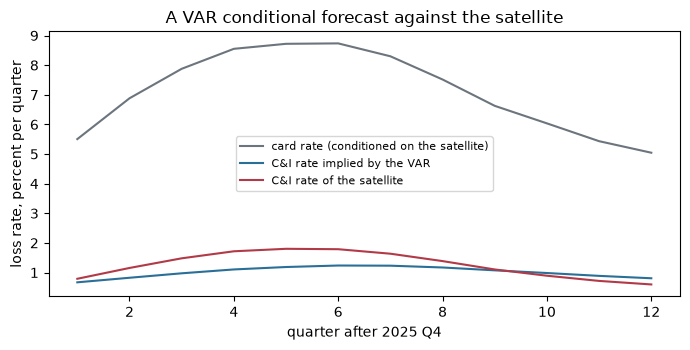

observations 24 eigenvalues of A_1 [0.865+0.128j 0.865-0.128j]


In [13]:
# A VAR(1) on the realised C&I and credit-card rates of 2020-2025, conditioned on the satellite path of the card rate
realised = {b["fed_loan_type"]: np.array([q["realised"] for q in b["quarters"]]) for b in backcast}
y = np.column_stack([realised["commercial-industrial"], realised["credit-cards"]])
var_fit = scenario_models.fit_var(y, 1)
card_path = committed_rates["credit-cards"].reshape(-1, 1)
conditional = scenario_models.var_conditional_forecast(var_fit, y[-1:], card_path, [1])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(quarters, card_path[:, 0] * 100, color="#6c757d", label="card rate (conditioned on the satellite)")
ax.plot(quarters, conditional[:, 0] * 100, color="#2a6f97", label="C&I rate implied by the VAR")
ax.plot(quarters, committed_rates["commercial-industrial"] * 100, color="#b23a48", label="C&I rate of the satellite")
ax.set_xlabel("quarter after 2025 Q4")
ax.set_ylabel("loss rate, percent per quarter")
ax.set_title("A VAR conditional forecast against the satellite")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("observations", y.shape[0], "eigenvalues of A_1", np.round(np.linalg.eigvals(var_fit.coefficients[0]), 3))

The VAR is fitted on only 24 quarters of realised rates, so it is a demonstration of the tool and not a finding. Conditioned
on the card rate following the satellite's path, it implies a commercial-and-industrial rate that rises to 1.24 percent a
quarter, while that loan type's own satellite, fitted on 139 quarters with macro regressors, reaches 1.80. Two models of the
same quantity, from different samples and different information, disagree by a third at the peak, which is a reason to keep a
challenger next to the champion and not a result about either. The eigenvalues of the VAR's coefficient matrix lie inside the
unit circle, so its forecast is stable.

### Step 7: growth-at-risk and the skewed-t density

**Growth-at-risk** (Adrian, Boyarchenko and Giannone 2019) builds a whole predictive distribution of GDP growth in two steps. Step 1 runs **quantile regressions** of average annualised growth on a constant, current growth and a financial-conditions index, one for each of the 5, 25, 75 and 95 percent quantiles. Step 2 fits the **Azzalini-Capitanio skewed-t** density

$$f(y;\mu,\sigma,\alpha,\nu) = \frac{2}{\sigma}\, t\!\left(\frac{y-\mu}{\sigma};\nu\right) T\!\left(\alpha\,\frac{y-\mu}{\sigma}\sqrt{\frac{\nu+1}{\nu+\left(\frac{y-\mu}{\sigma}\right)^2}};\ \nu+1\right)$$

to the four estimated quantiles by least squares, where $t$ and $T$ are the Student $t$ density and distribution function and $\alpha$ the skewness ($\alpha = 0$ is the Student t). Lower quantiles move strongly with financial conditions while the upper ones are stable, which makes the fitted density a **severity calibrator** for scenarios.

The engine has both steps. `gar_quantile_regressions` needs `statsmodels` (the optional `stress` extra of the engine) and a financial-conditions series; **neither is in the notebook environment or in the committed files**, so step 1 is not run here. Step 2, `fit_skewed_t_to_quantiles`, needs only four quantiles, and the next cell tests it two ways. First, the density at $\alpha = 0$ must equal the Student t and integrate to 1. Second, a known-truth fit: the quantiles of a normal distribution with the standard deviation of real GDP growth over 1985 to 2019 (the committed `factor_space`) should return $\alpha \approx 0$ and a large $\nu$; then a lower-tail-heavy set of quantiles, the shape growth-at-risk finds in stressed conditions (illustrative multiples of that standard deviation), should return a negative $\alpha$.

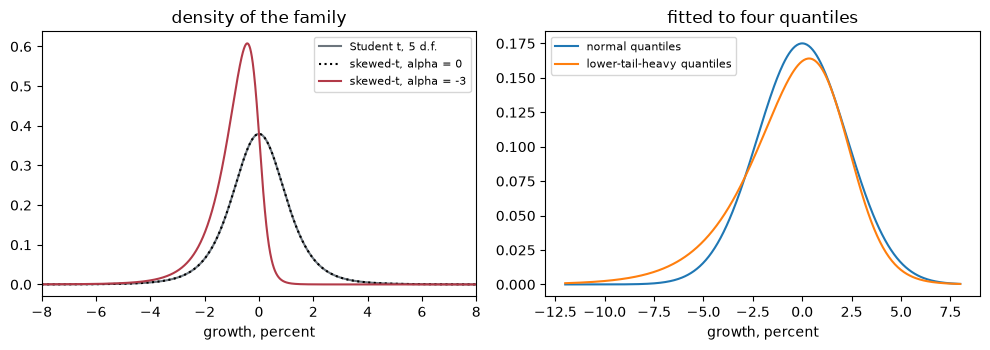

area under the alpha = -3 density 0.9999
normal quantiles: alpha, nu, sigma 1.4e-07 1000 2.279
lower-tail-heavy: alpha, nu, sigma -1.833 10.2 3.393


In [14]:
# Check the skewed-t density against the Student t, then fit it to known-truth and to lower-tail-heavy quantiles
z = np.linspace(-12, 12, 4001)
skew0 = scenario_models.skewed_t_pdf(z, 0.0, 1.0, 0.0, 5.0)
skew3 = scenario_models.skewed_t_pdf(z, 0.0, 1.0, -3.0, 5.0)
sd_growth = models["factor_space"]["factors"][0]["sd"]
taus = np.array([0.05, 0.25, 0.75, 0.95])
truth = scenario_models.fit_skewed_t_to_quantiles(stats.norm.ppf(taus) * sd_growth)
heavy = scenario_models.fit_skewed_t_to_quantiles(np.array([-2.4, -0.9, 0.6, 1.5]) * sd_growth)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(z, stats.t.pdf(z, 5), color="#6c757d", label="Student t, 5 d.f.")
axes[0].plot(z, skew0, "k:", label="skewed-t, alpha = 0")
axes[0].plot(z, skew3, color="#b23a48", label="skewed-t, alpha = -3")
axes[0].set_xlim(-8, 8)
axes[0].legend(fontsize=8)
grid_y = np.linspace(-12, 8, 400)
pdf_truth = scenario_models.skewed_t_pdf(grid_y, truth.mu, truth.sigma, truth.alpha, truth.nu)
pdf_heavy = scenario_models.skewed_t_pdf(grid_y, heavy.mu, heavy.sigma, heavy.alpha, heavy.nu)
axes[1].plot(grid_y, pdf_truth, label="normal quantiles")
axes[1].plot(grid_y, pdf_heavy, label="lower-tail-heavy quantiles")
axes[1].legend(fontsize=8)
for ax, title in zip(axes, ("density of the family", "fitted to four quantiles")):
    ax.set_title(title)
    ax.set_xlabel("growth, percent")
fig.tight_layout()
plt.show()
print("area under the alpha = -3 density", round(float(np.trapezoid(skew3, z)), 4))
print("normal quantiles: alpha, nu, sigma", f"{truth.alpha:.1e}", round(truth.nu), round(truth.sigma, 3))
print("lower-tail-heavy: alpha, nu, sigma", round(heavy.alpha, 3), round(heavy.nu, 2), round(heavy.sigma, 3))

In the left panel the skewed-t with alpha equal to zero sits exactly on the Student t, as it must, and a negative alpha
shifts the mass to the left tail while the density still integrates to 1 (0.9999 over the plotted range). In the right panel,
four normal quantiles with the 2.281 standard deviation of GDP growth return alpha of about zero and a degrees-of-freedom
parameter at the search ceiling of 1000, which is a normal in the limit; the lower-tail-heavy set returns alpha of minus 1.833
and 10.2 degrees of freedom, a left-skewed density. With four quantiles and four parameters the fit is exact, so what the
check shows is that the optimiser recovers a known truth, not that the shape is right for any real quarter.

## Results

The last figure puts the four scenarios side by side: the transposed unemployment path of each (left) and the credit-card loss
rate that the card satellite projects under each (right). The paths differ in shape and severity, and the satellite converts the
difference into a loss rate with a lag and a ceiling of its own.

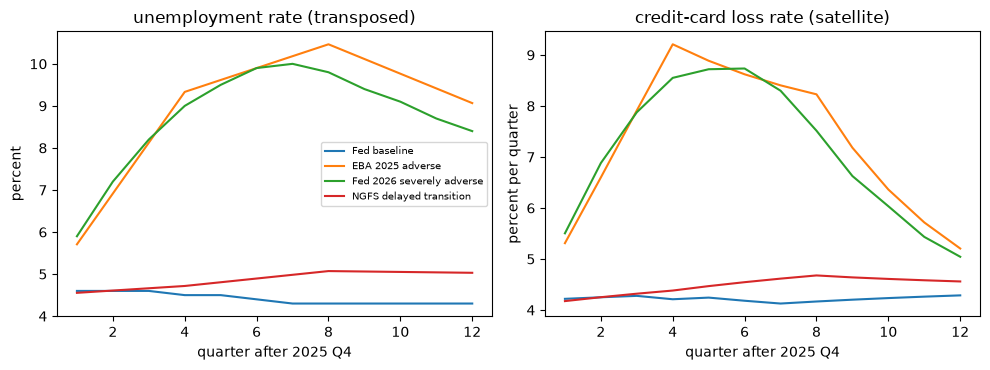

peak card loss rate by scenario, percent per quarter {'Fed baseline': 4.29, 'EBA 2025 adverse': 9.21, 'Fed 2026 severely adverse': 8.73, 'NGFS delayed transition': 4.68}


In [15]:
# Draw the transposed unemployment paths and the credit-card rate each scenario implies through the satellite
card_fit = fits["credit-cards"]
card_last = satellites.link("probit", np.array([last_rate["credit-cards"]]))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
peak = {}
for key in docs:
    p_u, p_g = path_of(key, "unemployment_rate"), path_of(key, "real_gdp_growth")
    u_path = np.array([row["value"] for row in p_u["transposed"]])
    x_path = np.column_stack([[row["value"] for row in p_g["transposed"]], u_path])
    start = np.array([[p_g["transposition"]["target"]["value"], p_u["transposition"]["target"]["value"]]])
    rates = satellites.project_scenario(card_fit, card_last, start, x_path).rates
    peak[SCENARIO[key]] = round(float(rates.max()) * 100, 2)
    axes[0].plot(quarters, u_path, label=SCENARIO[key])
    axes[1].plot(quarters, rates * 100, label=SCENARIO[key])
axes[0].set_title("unemployment rate (transposed)")
axes[0].set_ylabel("percent")
axes[1].set_title("credit-card loss rate (satellite)")
axes[1].set_ylabel("percent per quarter")
for ax in axes:
    ax.set_xlabel("quarter after 2025 Q4")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
print("peak card loss rate by scenario, percent per quarter", peak)

The ordering of the card loss rate follows the paths. The Federal Reserve baseline and the NGFS delayed transition stay near 4.3
to 4.7 percent a quarter because their unemployment paths are mild, and the two adverse scenarios double it. The EBA adverse
scenario comes out slightly above the Federal Reserve's severely adverse one, 9.21 against 8.73 percent, because once
transposed onto the bank's jump-off its growth trough, minus 6.82 percent, and its unemployment peak, 10.47, are deeper than
the Federal Reserve's. A scenario is only as severe as its path after it has been moved onto the bank, which is why step 2 to
4 come before any satellite.

**Answer:** a published scenario needs three things before a satellite can read it: a vintage on or before the observation date
(2026-08-31, which the engine enforces and which every committed scenario meets), a transposition of its shape onto the bank's
jump-off (none for the Federal Reserve, a linear annual-to-quarterly join and a shift of 0.42 points of unemployment for the
EBA, baseline plus a deviation for the NGFS) and a quarterly path of twelve quarters. With that, the card satellite projects a
peak quarterly loss rate of 4.29 percent in the Federal Reserve baseline and 4.68 percent under NGFS delayed transition, against
8.73 percent under the Federal Reserve severely adverse scenario and 9.21 percent under the EBA adverse one, and the credit loss
of Banco Andino in the severely adverse scenario is CLP 86,518.6, 111,986.8 and 71,005.1 million in its three years.

What this notebook does not show: the satellites were projected, not refitted, because the 1985 to 2019 history is not
committed; the first quantile-regression step of growth-at-risk was not run, because it needs `statsmodels` and a
financial-conditions series that this environment does not have; and none of these rates is a forecast for Chile, because paths
and coefficients are United States ones transposed onto a synthetic bank.

## Summary

- A macro stress test has three layers; this notebook covered the scenario paths and the satellites, and notebook 05 covers the capital engine.
- A path published after the observation date is refused by `check_vintage`; every committed vintage is on or before it.
- A published path is moved onto the bank's jump-off by keeping its shape: as it is for the Federal Reserve, after an annual-to-quarterly join for the EBA, and as a baseline plus a deviation for the NGFS. The engine reproduces each committed path.
- A probit satellite is a regression of the latent credit cycle on macro variables; with the committed coefficients the engine reproduces the committed loss rates and the bank's credit loss by year exactly, but the satellites cannot be refitted from the committed files.
- The VAR conditional forecast and the skewed-t fit of growth-at-risk are engine tools the case does not bake; their mechanics were run on committed data and known truth, and growth-at-risk's quantile regressions need `statsmodels` and a financial-conditions series that this environment does not have.

**What to try next.** Swap the scenario of step 5 for the EBA one and compare the peak loss rates of the five loan types. Then continue with notebook 05, which takes the losses and builds the capital plan.

## References

- EBA (2025), 2025 EU-wide stress test, Methodological Note of 2025-01-20: the static balance sheet (paragraphs 24, 33, 34 and 90 to 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- NGFS (2024), Climate scenarios, Phase V (launch). https://www.ngfs.net/en/news/ngfs-scenarios-phase-v-launch-event
- NGFS Phase V scenarios, IIASA Scenario Explorer (the NiGEM runs the case reads). https://data.ene.iiasa.ac.at/ngfs
- Adrian, T., Boyarchenko, N. and Giannone, D. (2019), Vulnerable growth, American Economic Review 109(4). https://doi.org/10.1257/aer.20161923
- Board of Governors of the Federal Reserve System (2026), 2026 supervisory severely adverse scenario, domestic (the quarterly macro path file). https://www.federalreserve.gov/supervisionreg/files/2026_Final_Supervisory_Severely_Adverse_Domestic.csv
- Dossiers 04 (I.1, the satellite and the Vasicek link) and 05 (H.1 and H.2, the three layers, the VAR and growth-at-risk) of the persisted Contraste research, as summarised in the SDD's research basis.
- This repository: `docs/contracts/engine/stress-api.md` (the path, satellite and scenario-model functions).